# Análise Exploratória — COVID-19 no Brasil por Unidade Federativa

**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python)
**Autor:** Marcelo Barbosa de Oliveira Junior

Este notebook documenta a exploração preliminar, prototipação e validação do
pipeline usado para o artigo final (`docs/index.html`). A versão de produção
do pipeline está em `src/etl.py` e `src/analysis.py`; este notebook é a
camada de investigação e checagem.

**Fonte dos dados:** Brasil.IO — dataset `covid19`/`caso_full` (ver
`data/data_dictionary.md` para a proveniência completa e a justificativa de
uso da cópia estruturada wcota/covid19br).

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from etl import run as run_etl, load_raw, clean_and_transform

pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (9, 5)

## 1. Ingestão e inspeção dos dados brutos

In [2]:
states_raw, cities_info_raw = load_raw()
print(states_raw.shape, cities_info_raw.shape)
states_raw.head()

(30842, 26) (5570, 11)


,epi_week,date,country,state,city,newDeaths,deaths,newCases,totalCases,deathsMS,totalCasesMS,deaths_per_100k_inhabitants,totalCases_per_100k_inhabitants,deaths_by_totalCases,recovered,suspects,tests,tests_per_100k_inhabitants,vaccinated,vaccinated_per_100_inhabitants,vaccinated_second,vaccinated_second_per_100_inhabitants,vaccinated_single,vaccinated_single_per_100_inhabitants,vaccinated_third,vaccinated_third_per_100_inhabitants
0,9,2020-02-25,Brazil,SP,TOTAL,0,0,1,1,0,0,0.0,0.00218,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,9,2020-02-25,Brazil,TOTAL,TOTAL,0,0,1,1,0,0,0.0,0.00047,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9,2020-02-26,Brazil,SP,TOTAL,0,0,0,1,0,1,0.0,0.00218,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,9,2020-02-26,Brazil,TOTAL,TOTAL,0,0,0,1,0,1,0.0,0.00047,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9,2020-02-27,Brazil,SP,TOTAL,0,0,0,1,0,1,0.0,0.00218,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Checagem de qualidade: valores ausentes por coluna
states_raw.isna().mean().sort_values(ascending=False).head(12)

vaccinated_third                         0.489916
vaccinated_third_per_100_inhabitants     0.489916
vaccinated_single                        0.421211
vaccinated_single_per_100_inhabitants    0.421211
vaccinated_second                        0.303677
vaccinated_second_per_100_inhabitants    0.303677
vaccinated                               0.283088
vaccinated_per_100_inhabitants           0.283088
tests                                    0.043253
tests_per_100k_inhabitants               0.043253
recovered                                0.020848
suspects                                 0.019259
dtype: float64

In [4]:
# Checagem: existe o agregado nacional 'TOTAL' que precisa ser removido no ETL?
states_raw['state'].value_counts().tail(5)

state
AP    1094
MA    1094
MT    1094
RO    1094
RR    1093
Name: count, dtype: int64[pyarrow]

## 2. Execução do pipeline de limpeza (src/etl.py)

In [5]:
df = clean_and_transform(states_raw, cities_info_raw)
print(f"Linhas: {len(df):,} | UFs: {df['state'].nunique()} | "
      f"Período: {df['date'].min().date()} -> {df['date'].max().date()}")
df.head()

Linhas: 29,724 | UFs: 27 | Período: 2020-02-25 -> 2023-03-18


,epi_week,date,country,state,city,newDeaths,deaths,newCases,totalCases,deathsMS,totalCasesMS,deaths_per_100k_inhabitants,totalCases_per_100k_inhabitants,deaths_by_totalCases,recovered,...,tests_per_100k_inhabitants,vaccinated,vaccinated_per_100_inhabitants,vaccinated_second,vaccinated_second_per_100_inhabitants,vaccinated_single,vaccinated_single_per_100_inhabitants,vaccinated_third,vaccinated_third_per_100_inhabitants,region,lethality_rate,cases_7d_avg,deaths_7d_avg,wave_phase,year
0,12,2020-03-17,Brazil,AC,TOTAL,0,0,3,3,0,0,0.0,0.34016,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Norte,0.0,3.000000,0.0,pré-vacinação,2020
1,12,2020-03-18,Brazil,AC,TOTAL,0,0,0,3,0,0,0.0,0.34016,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Norte,0.0,1.500000,0.0,pré-vacinação,2020
2,12,2020-03-19,Brazil,AC,TOTAL,0,0,1,4,0,3,0.0,0.45355,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Norte,0.0,1.333333,0.0,pré-vacinação,2020
3,12,2020-03-20,Brazil,AC,TOTAL,0,0,3,7,0,7,0.0,0.79371,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Norte,0.0,1.750000,0.0,pré-vacinação,2020
4,12,2020-03-21,Brazil,AC,TOTAL,0,0,4,11,0,9,0.0,1.24726,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Norte,0.0,2.200000,0.0,pré-vacinação,2020


## 3. Estatística descritiva (último dia da série, por UF)

In [6]:
last_day = df.sort_values('date').groupby('state').tail(1)
last_day[['state','region','totalCases_per_100k_inhabitants',
          'deaths_per_100k_inhabitants','lethality_rate',
          'vaccinated_per_100_inhabitants']].describe()

,totalCases_per_100k_inhabitants,deaths_per_100k_inhabitants,lethality_rate,vaccinated_per_100_inhabitants
count,27.000000,27.000000,27.000000,27.000000
mean,19712.400068,315.276668,0.017149,84.489599
std,7086.812075,80.591110,0.004674,6.382826
min,6973.927590,156.222150,0.011364,73.371080
25%,14668.493635,251.867775,0.013670,79.302890
50%,18193.177500,309.450830,0.015760,84.956740
75%,25788.794180,391.367720,0.019634,88.230760
max,32936.309460,445.133240,0.027902,96.646030


In [7]:
# Outliers: estados com letalidade aparente fora de 1.5*IQR
q1, q3 = last_day['lethality_rate'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
outliers = last_day[(last_day['lethality_rate'] < lower) | (last_day['lethality_rate'] > upper)]
outliers[['state','lethality_rate']].sort_values('lethality_rate', ascending=False)

,state,lethality_rate


## 4. Correlação: cobertura vacinal x letalidade aparente (RQ2)

Correlação de Pearson (cobertura vacinal x letalidade): 0.236


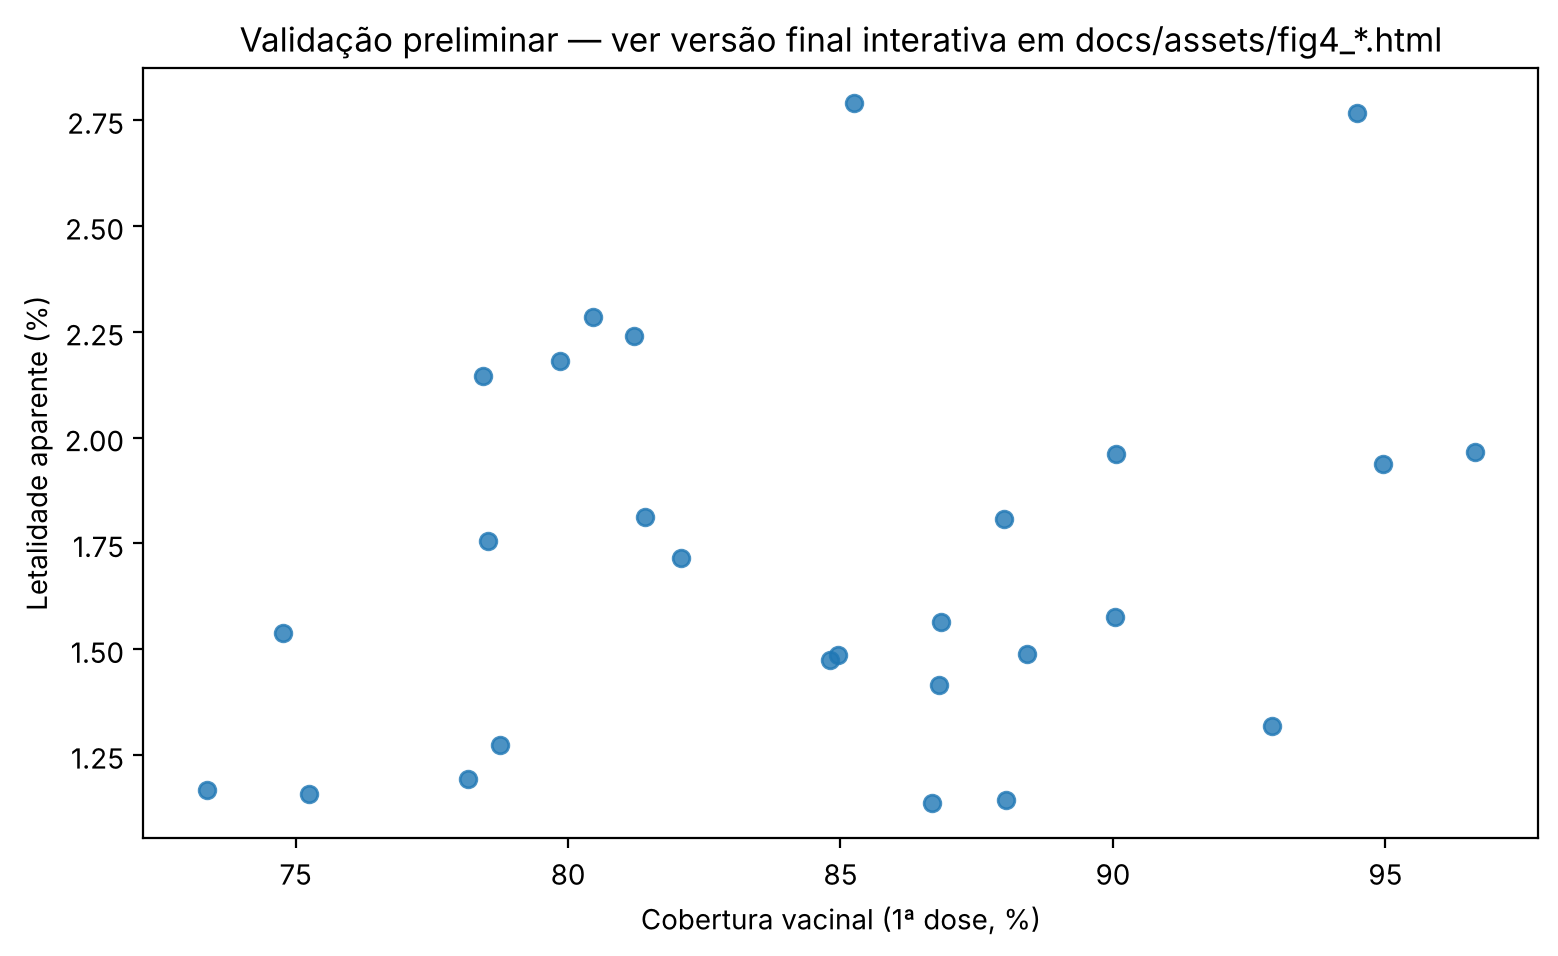

In [8]:
corr_df = last_day.dropna(subset=['vaccinated_per_100_inhabitants','lethality_rate'])
corr = corr_df['vaccinated_per_100_inhabitants'].corr(corr_df['lethality_rate'])
print(f"Correlação de Pearson (cobertura vacinal x letalidade): {corr:.3f}")

plt.scatter(corr_df['vaccinated_per_100_inhabitants'], corr_df['lethality_rate']*100, alpha=0.8)
plt.xlabel('Cobertura vacinal (1ª dose, %)')
plt.ylabel('Letalidade aparente (%)')
plt.title('Validação preliminar — ver versão final interativa em docs/assets/fig4_*.html')
plt.show()

## 5. Validação das médias móveis (ondas) — RQ1 e RQ3

Conferência visual de que `cases_7d_avg` suaviza corretamente o ruído de
subnotificação em finais de semana, preservando o formato das ondas
epidêmicas por região.

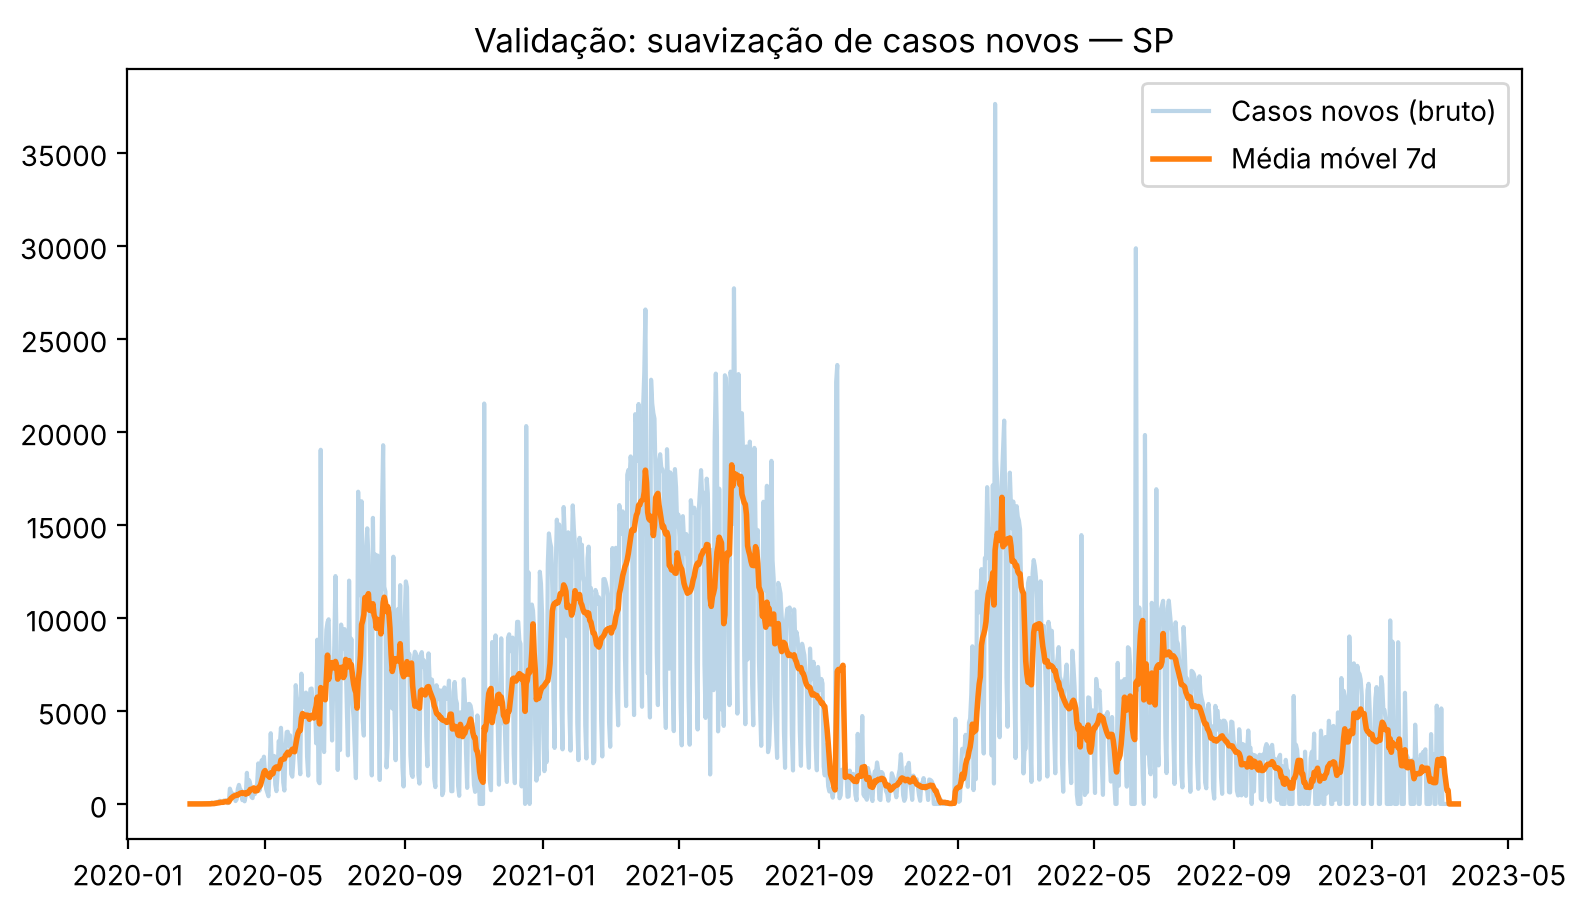

In [9]:
sp = df[df['state'] == 'SP']
fig, ax = plt.subplots()
ax.plot(sp['date'], sp['newCases'], alpha=0.3, label='Casos novos (bruto)')
ax.plot(sp['date'], sp['cases_7d_avg'], label='Média móvel 7d', linewidth=2)
ax.legend()
ax.set_title('Validação: suavização de casos novos — SP')
plt.show()

## 6. Conclusão da etapa exploratória

Os dados foram validados quanto a: completude estrutural (27 UFs, série
contínua), ausência de duplicidade (remoção do agregado `TOTAL`), e
coerência das métricas derivadas (letalidade, médias móveis). O pipeline
`src/etl.py` reproduz estes mesmos passos de forma determinística e
persiste o resultado em `data/processed/`. As figuras finais usadas no
artigo são geradas por `src/analysis.py`.